# Name That LLM — baseline z Qwen

Plan:
1. **TF-IDF + regresja logistyczna** (punkt odniesienia, bez LLM)
2. **Qwen jako ekstraktor cech** (średnia z ukrytych stanów z kilku warstw) + regresja logistyczna
3. **Blend** obu modeli, walidacja `GroupKFold` po `prompt_id` (test ma inne prompty niż train!)
4. Predykcja na teście i zapis `submission.parquet`

**Przed uruchomieniem:** w notebooku Kaggle dodaj dane konkursu oraz model Qwen (*Add Input → Models → Qwen3 / transformers*). Przy ponownym uruchomieniu na ukrytym teście nie ma internetu, więc model musi być podłączony jako input.

In [ ]:
import os, re, getpass, zipfile, pathlib

raw = getpass.getpass("Wklej token Kaggle: ")
m = re.search(r"KGAT_[0-9A-Za-z]+", raw)
assert m, "Nie znalazłem tokenu zaczynającego się od KGAT_"
os.environ["KAGGLE_API_TOKEN"] = m.group(0)   # nadpisuje błędną wartość z poprzedniej próby

from kaggle.api.kaggle_api_extended import KaggleApi

OUT = pathlib.Path("data"); OUT.mkdir(exist_ok=True)
api = KaggleApi(); api.authenticate()
api.competition_download_files("name-that-llm", path=OUT, quiet=False)
z = OUT / "name-that-llm.zip"
zipfile.ZipFile(z).extractall(OUT); z.unlink()
print(sorted(p.name for p in OUT.iterdir()))

Wklej token Kaggle: ··········


100%|██████████| 854k/854k [00:01<00:00, 841kB/s]


['sample_submission.parquet', 'test.csv', 'train.csv']


In [ ]:
import os, glob, time, gc, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

# --- konfiguracja ---
COMP_DIR = "/content/data"
if not os.path.exists(COMP_DIR):
    hits = glob.glob("/kaggle/input/*/train.csv")
    COMP_DIR = os.path.dirname(hits[0]) if hits else "."

QWEN_DIR_OVERRIDE = None      # możesz wpisać ścieżkę ręcznie
PREFER = "0.6b"               # np. "0.6b", "1.7b" – fragment ścieżki wybranego modelu
MAX_LEN = 512
BATCH = 16
N_FOLDS = 20
SEED = 42
OUT_DIR = "/" if os.path.exists("/kaggle/working") else "."
print("Dane:", COMP_DIR, "| wyjście:", OUT_DIR)

: 

## 1. Dane

In [ ]:
train = pd.read_csv(f"{COMP_DIR}/train.csv")
test = pd.read_csv(f"{COMP_DIR}/test.csv")
print(train.shape, test.shape)
display(train.model.value_counts())
display(train.text.str.len().describe())
display(train.groupby("model").text.apply(lambda s: s.str.len().median()).sort_values().to_frame("mediana_dlugosc"))

(2699, 4) (3, 2)


,count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150


,text
count,2699.000000
mean,755.289366
std,377.371075
min,230.000000
25%,429.000000
50%,670.000000
75%,1027.000000
max,1900.000000


,mediana_dlugosc
model,
gemini-3.8-flash,583.0
kimi-k3,594.5
glm-5.3,616.5
qwen3.8-max,625.0
gemini-3.6-flash,634.5
gpt-5.5,643.5
claude-fable-5,646.0
gpt-5.6-terra,648.5
gpt-5.6-luna,673.0


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, log_loss

le = LabelEncoder()
y = le.fit_transform(train.model.values)
K = len(le.classes_)
groups = train.prompt_id.values
folds = list(GroupKFold(n_splits=N_FOLDS).split(train, y, groups))
X_text = train.text.values
print("Klasy:", K)

def report(name, P, y=y):
    pred = P.argmax(1)
    print(f"{name:<28} acc={accuracy_score(y, pred):.4f}  macroF1={f1_score(y, pred, average='macro'):.4f}  logloss={log_loss(y, np.clip(P, 1e-6, 1), labels=range(K)):.4f}")

def run_cv(make_model, X, name):
    oof = np.zeros((len(y), K))
    for i, (tr, va) in enumerate(folds):
        t0 = time.time()
        m = make_model()
        m.fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])
        print(f"  [{name}] fold {i+1}/{N_FOLDS}  acc={accuracy_score(y[va], oof[va].argmax(1)):.4f}  ({time.time()-t0:.0f}s)")
    report(name, oof)
    return oof

Klasy: 18


## 2. Baseline: TF-IDF (znaki + słowa)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression

def make_tfidf():
    feats = make_union(
        TfidfVectorizer(analyzer="char", ngram_range=(1, 4), lowercase=False,
                        sublinear_tf=True, min_df=2, max_features=300_000),
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False,
                        token_pattern=r"\S+", sublinear_tf=True, min_df=2),
    )
    return make_pipeline(feats, LogisticRegression(C=20, max_iter=2000))

oof_tfidf = run_cv(make_tfidf, X_text, "tfidf+LR")

  [tfidf+LR] fold 1/20  acc=0.2986  (33s)
  [tfidf+LR] fold 2/20  acc=0.3472  (37s)
  [tfidf+LR] fold 3/20  acc=0.3889  (27s)
  [tfidf+LR] fold 4/20  acc=0.3333  (34s)
  [tfidf+LR] fold 5/20  acc=0.3333  (41s)
  [tfidf+LR] fold 6/20  acc=0.3889  (31s)
  [tfidf+LR] fold 7/20  acc=0.3333  (31s)
  [tfidf+LR] fold 8/20  acc=0.3750  (28s)
  [tfidf+LR] fold 9/20  acc=0.3472  (32s)
  [tfidf+LR] fold 10/20  acc=0.3846  (34s)
  [tfidf+LR] fold 11/20  acc=0.3413  (30s)
  [tfidf+LR] fold 12/20  acc=0.3651  (31s)
  [tfidf+LR] fold 13/20  acc=0.3413  (32s)
  [tfidf+LR] fold 14/20  acc=0.3254  (28s)
  [tfidf+LR] fold 15/20  acc=0.3254  (31s)
  [tfidf+LR] fold 16/20  acc=0.3492  (28s)
  [tfidf+LR] fold 17/20  acc=0.3254  (38s)
  [tfidf+LR] fold 18/20  acc=0.3095  (36s)
  [tfidf+LR] fold 19/20  acc=0.3889  (39s)
  [tfidf+LR] fold 20/20  acc=0.3730  (28s)
tfidf+LR                     acc=0.3490  macroF1=0.3420  logloss=2.0414


## 3. Qwen jako ekstraktor cech

Dla każdego tekstu liczymy średnią (z maską paddingu) ukrytych stanów z trzech warstw: ~50%, ~75% i ostatniej, po czym je sklejamy. Środkowe warstwy zwykle niosą więcej informacji o stylu niż ostatnia.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel

QWEN_DIR = "Qwen/Qwen3-4B"      # pobierze się z Hugging Face (ok. 1,5 GB)

device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(QWEN_DIR)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
qwen = AutoModel.from_pretrained(
    QWEN_DIR, torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()

n_layers = qwen.config.num_hidden_layers
LAYERS = sorted({n_layers // 2, (3 * n_layers) // 4, n_layers})
print("device:", device, "| warstwy:", LAYERS, "| hidden:", qwen.config.hidden_size)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

device: cuda | warstwy: [18, 27, 36] | hidden: 2560


In [ ]:
@torch.no_grad()
def embed(texts, bs=BATCH, max_len=MAX_LEN):
    texts = list(texts)
    order = np.argsort([len(t) for t in texts])[::-1]   # od najdłuższych: mniej paddingu, szybciej
    out = [None] * len(texts)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        b = tok([texts[j] for j in idx], padding=True, truncation=True,
                max_length=max_len, return_tensors="pt").to(device)
        hs = qwen(**b, output_hidden_states=True).hidden_states
        m = b["attention_mask"].unsqueeze(-1).float()
        feats = []
        for l in LAYERS:
            h = hs[l].float()                       # sumowanie w fp32 (unik overflow w fp16)
            feats.append((h * m).sum(1) / m.sum(1))
        f = torch.cat(feats, dim=1).cpu().numpy()
        for k, j in enumerate(idx):
            out[j] = f[k]
        if (i // bs) % 20 == 0:
            print(f"  {i}/{len(texts)}", end="\r")
    return np.vstack(out)

tag = os.path.basename(QWEN_DIR.rstrip("/")) + f"_L{MAX_LEN}"
p_tr = f"{OUT_DIR}/emb_train_{tag}.npy"
if os.path.exists(p_tr):
    E_train = np.load(p_tr)
else:
    t0 = time.time()
    E_train = embed(train.text.values)
    np.save(p_tr, E_train)
    print(f"\nGotowe w {time.time()-t0:.0f}s")
print(E_train.shape)


Gotowe w 224s
(2699, 7680)


In [ ]:
from sklearn.preprocessing import StandardScaler

def make_qwen_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))

oof_qwen = run_cv(make_qwen_clf, E_train, "qwen-emb+LR")

  [qwen-emb+LR] fold 1/20  acc=0.3403  (37s)
  [qwen-emb+LR] fold 2/20  acc=0.4167  (35s)
  [qwen-emb+LR] fold 3/20  acc=0.3542  (35s)
  [qwen-emb+LR] fold 4/20  acc=0.3264  (37s)
  [qwen-emb+LR] fold 5/20  acc=0.3542  (36s)
  [qwen-emb+LR] fold 6/20  acc=0.3819  (34s)
  [qwen-emb+LR] fold 7/20  acc=0.3542  (35s)
  [qwen-emb+LR] fold 8/20  acc=0.3194  (34s)
  [qwen-emb+LR] fold 9/20  acc=0.4236  (36s)
  [qwen-emb+LR] fold 10/20  acc=0.4266  (33s)
  [qwen-emb+LR] fold 11/20  acc=0.2698  (36s)
  [qwen-emb+LR] fold 12/20  acc=0.3413  (34s)
  [qwen-emb+LR] fold 13/20  acc=0.4048  (35s)
  [qwen-emb+LR] fold 14/20  acc=0.3571  (32s)
  [qwen-emb+LR] fold 15/20  acc=0.3810  (37s)
  [qwen-emb+LR] fold 16/20  acc=0.3730  (35s)
  [qwen-emb+LR] fold 17/20  acc=0.3492  (35s)
  [qwen-emb+LR] fold 18/20  acc=0.4048  (35s)
  [qwen-emb+LR] fold 19/20  acc=0.3730  (35s)
  [qwen-emb+LR] fold 20/20  acc=0.4365  (34s)
qwen-emb+LR                  acc=0.3694  macroF1=0.3679  logloss=2.4109


## 4. Blend

w_tfidf=0.0  acc=0.3694  logloss=2.4109
w_tfidf=0.1  acc=0.3709  logloss=2.0319
w_tfidf=0.2  acc=0.3727  logloss=1.9261
w_tfidf=0.3  acc=0.3757  logloss=1.8688
w_tfidf=0.4  acc=0.3768  logloss=1.8376
w_tfidf=0.5  acc=0.3842  logloss=1.8248
w_tfidf=0.6  acc=0.3920  logloss=1.8276
w_tfidf=0.7  acc=0.4016  logloss=1.8457
w_tfidf=0.8  acc=0.4113  logloss=1.8812
w_tfidf=0.9  acc=0.4027  logloss=1.9401
w_tfidf=1.0  acc=0.3490  logloss=2.0414
Wybrana waga TF-IDF: 0.5
blend                        acc=0.3842  macroF1=0.3821  logloss=1.8248


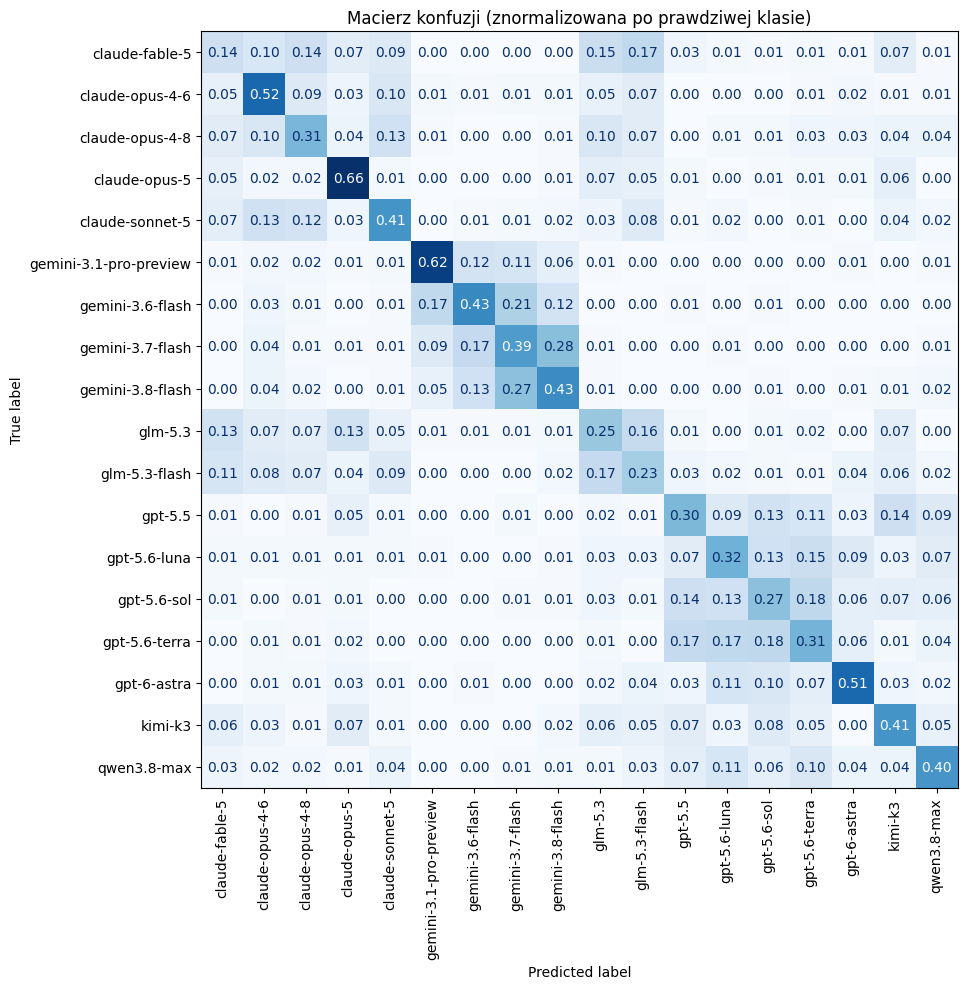

In [ ]:
best = None
for w in np.linspace(0, 1, 11):
    P = w * oof_tfidf + (1 - w) * oof_qwen
    ll = log_loss(y, np.clip(P, 1e-6, 1), labels=range(K))
    acc = accuracy_score(y, P.argmax(1))
    print(f"w_tfidf={w:.1f}  acc={acc:.4f}  logloss={ll:.4f}")
    if best is None or ll < best[0]:
        best = (ll, w)
W = best[1]
print("Wybrana waga TF-IDF:", W)
report("blend", W * oof_tfidf + (1 - W) * oof_qwen)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

pred = (W * oof_tfidf + (1 - W) * oof_qwen).argmax(1)
fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(
    y, pred, display_labels=le.classes_, normalize="true",
    values_format=".2f", cmap="Blues", xticks_rotation=90, ax=ax, colorbar=False,
)
ax.set_title("Macierz konfuzji (znormalizowana po prawdziwej klasie)")
plt.tight_layout(); plt.show()

## 5. Trening na całym train + predykcja testu

---



In [ ]:
tfidf_final = make_tfidf().fit(X_text, y)
qwen_final = make_qwen_clf().fit(E_train, y)

E_test = embed(test.text.values)
P_test = W * tfidf_final.predict_proba(test.text.values) + (1 - W) * qwen_final.predict_proba(E_test)

sub = pd.DataFrame({"id": test["id"].values, "model": le.inverse_transform(P_test.argmax(1))})
sub.to_parquet(f"{OUT_DIR}/submission.parquet", index=False)
display(sub.head())
print(sub.shape)

,id,model
0,00353fb1c541,claude-opus-4-8
1,005f5a9a6139,claude-opus-4-6
2,0062a53d5487,gemini-3.6-flash


(3, 2)


## Co dalej (jeśli baseline działa)
- większy Qwen (1.7B / 4B) albo więcej warstw w cechach,
- **fine-tuning LoRA** z `AutoModelForSequenceClassification(num_labels=18)`, walidacja nadal po `prompt_id`,
- dołożenie cech „meta": długość, liczba akapitów, listy/markdown, emoji, rodzaj cudzysłowów i myślników,
- ensemble z kilkoma seedami.

In [ ]:
from sklearn.metrics import balanced_accuracy_score, recall_score

P_blend = W * oof_tfidf + (1 - W) * oof_qwen
pred = P_blend.argmax(1)

print("balanced accuracy:", round(balanced_accuracy_score(y, pred), 4))

# recall dla każdego modelu osobno (to jest to, co jest uśredniane)
rec = recall_score(y, pred, average=None, labels=range(K))
display(pd.Series(rec, index=le.classes_, name="recall").sort_values().to_frame())

balanced accuracy: 0.3841


,recall
claude-fable-5,0.140940
glm-5.3-flash,0.233333
glm-5.3,0.253333
gpt-5.6-sol,0.273333
gpt-5.5,0.300000
claude-opus-4-8,0.306667
gpt-5.6-terra,0.313333
gpt-5.6-luna,0.320000
gemini-3.7-flash,0.386667
qwen3.8-max,0.400000
